# MuFilter Digitization & Physics Calibration Validation
**SND@LHC MuFilter Hardware Model & In-Situ Collision Validation**

---

### 1. Hardware Architecture & Trigger Threshold Parameters

The single-SiPM instantaneous discriminator threshold in photoelectrons ($N_{\mathrm{p.e.}}^{\mathrm{th}}$) is determined by the ratio of the discriminator voltage threshold to the single-photoelectron analog pulse height:

$$N_{\mathrm{p.e.}}^{\mathrm{th}} = \frac{v_{\mathrm{th}}}{V_{1\,\mathrm{p.e.}}} = \frac{\mathrm{thr} \times \mathrm{LSB}}{I_{1\,\mathrm{p.e.}}\cdot f_{\mathrm{peak}} \times g_t}$$

#### Exact Parameter Values and Physical Origins:

1. **Numerator (Voltage Threshold):**
   - **`thr_t1` & `thr_t2`**: Software-tunable 6-bit DAC register ($0 \le \mathrm{thr} \le 63$).
     - *TI18 Collision Data (Run 2022/2023)*: $\mathbf{20\text{ DAC counts}}$ (`DEFAULT_THR_T1 = 20`, `DEFAULT_THR_T2 = 20`).
     - *SPS H8 Testbeam (2023)*: $\mathbf{30\text{ DAC counts}}$ (raised to suppress room-temperature thermal dark count rate in $6\times 6\text{ mm}^2$ MPPCs).
     - *Source*: SND@LHC DAQ configuration (`thresholds.csv`) and `sndsw/shipLHC/rawMapping.py`.
   - **`lsb_thr_t1` & `lsb_thr_t2`**: 6-bit configuration register selecting the bias current for the DAC resistor ladder.
     - $\mathbf{\mathrm{lsb\_thr\_t1} = 59}$ (`DEFAULT_LSB_THR_T1 = 59`).
     - $\mathbf{\mathrm{lsb\_thr\_t2} = 50}$ (`DEFAULT_LSB_THR_T2 = 50`).
     - *Source*: SND@LHC DAQ configuration (`board.toml`) and PETsys TOFPET 2C ASIC Datasheet Rev 18, Table 12, p. 28.
   - **`LSB_t1` & `LSB_t2`**: Physical step size ($\mathrm{mV / DAC count}$) from piecewise-linear DAC calibration curve:
     - For T2 ($\mathrm{lsb\_thr} = 50$): $\mathbf{\mathrm{LSB}_{t2} = 8.50\text{ mV / count}}$.
     - For T1 ($\mathrm{lsb\_thr} = 59$): Interpolated between 57 ($5.81\text{ mV}$) and 60 ($3.23\text{ mV}$):
       $$\mathbf{\mathrm{LSB}_{t1} = 4.09\text{ mV / count}}$$
     - *Source*: TOFPET2 Experimental Characterization Paper (*2019 JINST 14 P03029*, Fig. 6).
   - **Total Voltage Threshold ($v_{\mathrm{th}} = \mathrm{thr} \times \mathrm{LSB}$):**
     - TI18: $v_{\mathrm{th\_t1}} = 20 \times 4.09 = \mathbf{81.8\text{ mV}}$, $v_{\mathrm{th\_t2}} = 20 \times 8.50 = \mathbf{170.0\text{ mV}}$.
     - Testbeam: $v_{\mathrm{th\_t1}} = 30 \times 4.09 = \mathbf{122.7\text{ mV}}$, $v_{\mathrm{th\_t2}} = 30 \times 8.50 = \mathbf{255.0\text{ mV}}$.

2. **Denominator (Single-Photoelectron Signal Amplitude):**
   - **$g_t$ (Amplifier Transimpedance Gain):**
     - $\mathbf{g_t = 3000\,\Omega = 3.0\text{ mV / }\mu\text{A}}$ (`DEFAULT_G_T_OHMS = 3000.0`).
     - *Source*: PETsys TOFPET2C Datasheet Rev 18, Table 4, p. 11.
   - **$I_{1\,\mathrm{p.e.}}$ (Peak 1 p.e. SiPM Current):**
     - Peak instantaneous avalanche current: $\mathbf{I_{1\,\mathrm{p.e.}} = 5.0\,\mu\text{A}}$ (`DEFAULT_I_1PE_UA = 5.0`).
     - *Source*: Hamamatsu MPPC S13360-6050PE Datasheet ($6 \times 6\text{ mm}^2$, $50\,\mu\text{m}$ pitch, $M = 1.7 \times 10^6$).
   - **$f_{\mathrm{peak}}$ (Scintillation Pulse Convolution):**
     - EJ-200 PVT scintillator rise time $\tau_{\mathrm{rise}} = 0.9\text{ ns}$ and decay time $\tau_{\mathrm{decay}} = 2.1\text{ ns}$.
     - Normalization peak factor: $f_{\mathrm{peak}} = (\tau_{\mathrm{rise}} / \tau_{\mathrm{decay}})^{\frac{\tau_{\mathrm{rise}}}{\tau_{\mathrm{decay}} - \tau_{\mathrm{rise}}}} = \mathbf{0.4530}$.
     - Effective peak current: $I_{1\,\mathrm{p.e.}}^{\mathrm{eff}} = 5.0\,\mu\text{A} \times 0.4530 = \mathbf{2.265\,\mu\text{A}}$.
   - **Single p.e. Voltage at Discriminator ($V_{1\,\mathrm{p.e.}} = I_{1\,\mathrm{p.e.}}^{\mathrm{eff}} \times g_t$):**
     - $V_{1\,\mathrm{p.e.}} = 2.265\,\mu\text{A} \times 3.0\text{ mV/}\mu\text{A} = \mathbf{6.795\text{ mV / p.e.}}$

3. **Resulting SiPM Threshold ($N_{\mathrm{p.e.}}^{\mathrm{th}} = v_{\mathrm{th\_t2}} / V_{1\,\mathrm{p.e.}}$):**
   - **TI18 Physics**: $\mathbf{25.02\text{ p.e.}}$
   - **SPS H8 Testbeam**: $\mathbf{37.53\text{ p.e.}}$

---

### Structure of This Validation Notebook:
1. **Validation 1: SPS H8 Testbeam Hadronic Shower Digitization** (Incremental factor evolution and multiplicity distributions).
2. **Validation 2: Inclusive PMU Muon Events** (Luminosity-scaled direct comparison with Run 5408 data, $1.5307\text{ pb}^{-1}$).
3. **Validation 3: Transverse Lateral Spread of Radiative Muon Showers** (Perpendicular hit probability $P(\text{hit} \mid r_\perp)$).


In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

import ROOT
ROOT.gROOT.SetBatch(True)
ROOT.PyConfig.IgnoreCommandLineOptions = True

# Style setup
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14,
    "figure.autolayout": False,
})

_repo_root = os.path.dirname(os.path.abspath(""))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

import scripts.qdc_calib.min_pe as mpe
print(f"MinPE Module Loaded. Effective speed of light: {mpe.PROP_SPEED_CM_NS} cm/ns")


MinPE Module Loaded. Effective speed of light: 13.9 cm/ns


In [2]:
# Load cached testbeam data & Monte Carlo shower extractions
cache_path = os.path.join(_repo_root, "data/tb_mufi_mult_cache.npz")

if not os.path.exists(cache_path):
    print("Extracting fresh testbeam dataset...")
    import scripts.qdc_calib.generate_mufi_digi_plots as gmp
    data_dict = gmp.run_extraction(n_data_entries=35000, n_mc_events=600)
    np.savez_compressed(cache_path, **data_dict)
else:
    print(f"Loading cached testbeam dataset from {cache_path}...")
    npz = np.load(cache_path, allow_pickle=True)
    data_dict = {k: npz[k] for k in npz.files}

n_d = int(data_dict["n_showers_d"])
n_mc = int(data_dict["n_mc_events"])
stage_names = list(data_dict["stage_names"])

print(f"Testbeam: {n_d} Data showers (Run 100671) and {n_mc} MC events (180 GeV pi+).")


Loading cached testbeam dataset from /afs/cern.ch/work/i/idioniso/snd-numu-charm/data/tb_mufi_mult_cache.npz...
Testbeam: 1542 Data showers (Run 100671) and 600 MC events (180 GeV pi+).


---
## Validation 1: SPS H8 180 GeV $\pi^+$ Testbeam Shower Validation

### 1.1 Incremental Factor Evolution (US Plane 0)
- **Top-left panel (US0 Profile)**: Data as **black markers with error bars**; **Stage 8** with **vertical error bars**; filled histograms with high transparency (`alpha=0.15`) for each colormap curve.
- **Top-right panel (US0 Multiplicity)**: Multiplicity evolution with high-transparency filled distributions for all 8 stages.
- **Bottom-left panel (Waterfall)**: Progressive mean fired bars ($9.07 \rightarrow 4.37$, Data target $4.01$).
- **Bottom-right panel (Wing Splash)**: Firing probability of peripheral bars (0, 1, 8, 9) dropping from $56.5\%$ to $10.2\%$ (Data $6.6\%$).


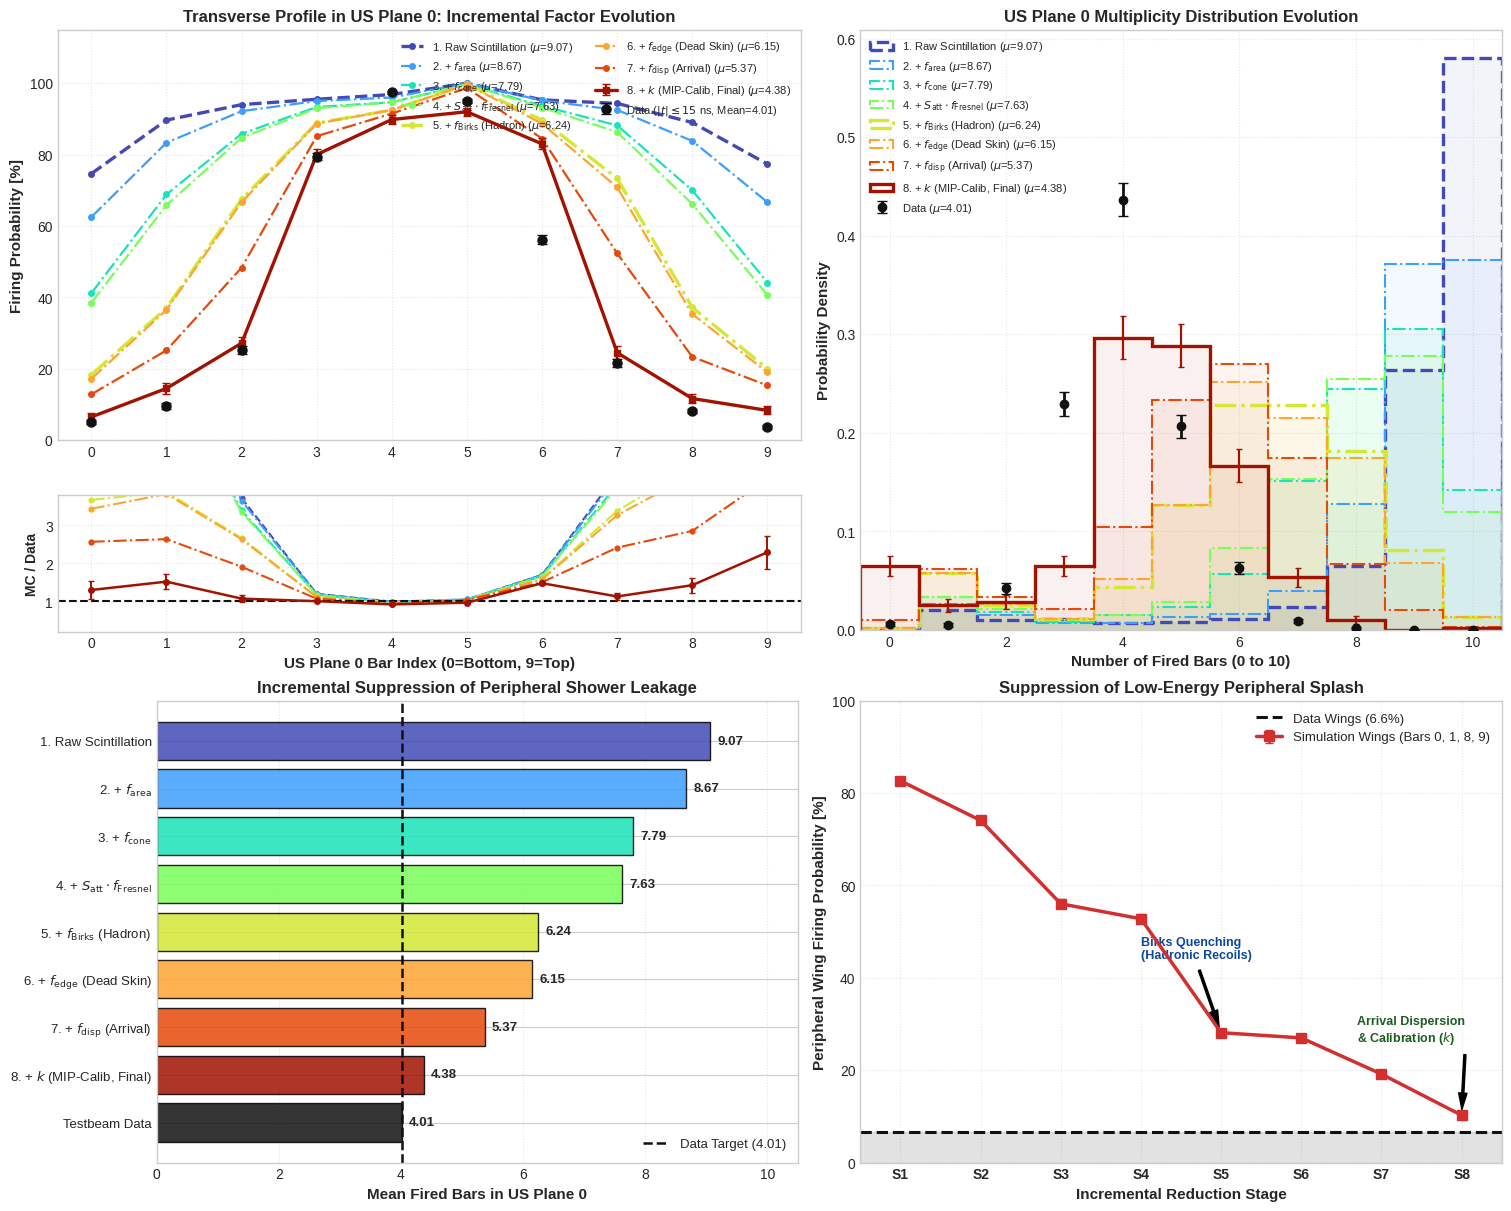

In [3]:
d_prob_bars = (data_dict["d_us0_bars"] / n_d) * 100.0
d_prob_err = np.sqrt(d_prob_bars * (100.0 - d_prob_bars) / n_d)
mean_d_mult = float(np.mean(data_dict["d_us0_mult"]))

mc_prob_bars = [(bars / n_mc) * 100.0 for bars in data_dict["mc_us0_bars"]]
mc_prob_err = [np.sqrt(pb * (100.0 - pb) / n_mc) for pb in mc_prob_bars]
mc_means = [float(np.mean(m)) for m in data_dict["mc_us0_mult"]]

fig = plt.figure(figsize=(15, 12), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1.0])

cmap = plt.cm.turbo
stage_colors = [cmap(val) for val in np.linspace(0.08, 0.95, 8)]

# -------------------------------------------------------------------------
# Panel 1: US Plane 0 Transverse Profile (Bar 0 to 9) with Subpanel Ratio
# -------------------------------------------------------------------------
gs_left = gs[0, 0].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.06)
ax_top = fig.add_subplot(gs_left[0])
ax_bot = fig.add_subplot(gs_left[1], sharex=ax_top)

x_bars = np.arange(10)

# Ratio for Stage 8 error propagation
ratio_s8 = np.where(d_prob_bars > 0.5, mc_prob_bars[7] / d_prob_bars, np.nan)
ratio_s8_err = ratio_s8 * np.sqrt(
    (mc_prob_err[7] / np.maximum(mc_prob_bars[7], 1e-6))**2 + 
    (d_prob_err / np.maximum(d_prob_bars, 1e-6))**2
)

for s_idx in range(8):
    c = stage_colors[s_idx]
    lw = 2.4 if s_idx in (0, 4, 7) else 1.6
    ls = "-" if s_idx == 7 else ("--" if s_idx == 0 else "-.")
    
    # Incremental curve (NO filled area on upper-left plot)
    if s_idx == 7:  # Stage 8: include vertical error bars
        ax_top.errorbar(
            x_bars, mc_prob_bars[s_idx], yerr=mc_prob_err[s_idx],
            marker="s", markersize=5.0, lw=lw, ls=ls, color=c,
            ecolor=c, elinewidth=1.6, capsize=3.0,
            label=f"{stage_names[s_idx]} ($\mu$={mc_means[s_idx]:.2f})",
            zorder=6
        )
        # Ratio to Data in bottom subpanel with vertical errors on red curve
        ax_bot.errorbar(
            x_bars, ratio_s8, yerr=ratio_s8_err,
            marker="o", markersize=4.0, lw=1.8, ls=ls, color=c,
            ecolor=c, elinewidth=1.4, capsize=2.5, zorder=6
        )
    else:
        ax_top.plot(
            x_bars, mc_prob_bars[s_idx],
            marker="o", markersize=4.0, lw=lw, ls=ls, color=c,
            label=f"{stage_names[s_idx]} ($\mu$={mc_means[s_idx]:.2f})",
            zorder=4
        )
        # Ratio to Data in bottom subpanel
        ratio = np.where(d_prob_bars > 0.5, mc_prob_bars[s_idx] / d_prob_bars, np.nan)
        ax_bot.plot(x_bars, ratio, marker="o", markersize=3.5, lw=1.5, ls=ls, color=c)

# Data as black markers with error bars
ax_top.errorbar(
    x_bars, d_prob_bars, yerr=d_prob_err,
    fmt="o", color="#111111", ecolor="#111111", elinewidth=2.0, capsize=3.5,
    markersize=6.5, label=f"Data ($|t|\leq 15$ ns, Mean={mean_d_mult:.2f})",
    zorder=10
)

ax_top.set_ylabel("Firing Probability [%]", fontsize=11, fontweight="bold")
ax_top.set_title("Transverse Profile in US Plane 0: Incremental Factor Evolution", fontsize=12, fontweight="bold")
ax_top.grid(True, linestyle=":", alpha=0.5)
ax_top.set_ylim(0, 115)
ax_top.legend(fontsize=8.0, loc="upper right", framealpha=0.92, ncol=2)

ax_bot.axhline(1.0, color="#111111", lw=1.5, linestyle="--")
ax_bot.set_ylabel("MC / Data", fontsize=10, fontweight="bold")
ax_bot.set_xlabel("US Plane 0 Bar Index (0=Bottom, 9=Top)", fontsize=11, fontweight="bold")
ax_bot.set_ylim(0.2, 3.8)
ax_bot.set_xticks(x_bars)
ax_bot.grid(True, linestyle=":", alpha=0.5)

# -------------------------------------------------------------------------
# Panel 2: Hit Multiplicity Distribution (Fired Bars in US Plane 0)
# -------------------------------------------------------------------------
ax_mult = fig.add_subplot(gs[0, 1])
bins_mult = np.arange(-0.5, 11.5, 1.0)
mult_centers = np.arange(11)

for s_idx in range(8):
    c = stage_colors[s_idx]
    lw = 2.4 if s_idx in (0, 4, 7) else 1.5
    ls = "-" if s_idx == 7 else ("--" if s_idx == 0 else "-.")
    # More transparent filled histogram (alpha=0.06)
    ax_mult.hist(
        data_dict["mc_us0_mult"][s_idx], bins=bins_mult, density=True,
        histtype="stepfilled", color=c, alpha=0.06,
    )
    ax_mult.hist(
        data_dict["mc_us0_mult"][s_idx], bins=bins_mult, density=True,
        histtype="step", lw=lw, ls=ls, color=c,
        label=f"{stage_names[s_idx]} ($\mu$={mc_means[s_idx]:.2f})",
    )

# Vertical error bars on red histogram (Stage 8)
counts_s8, _ = np.histogram(data_dict["mc_us0_mult"][7], bins=bins_mult)
prob_s8 = counts_s8 / n_mc
err_s8 = np.sqrt(counts_s8) / n_mc
ax_mult.errorbar(
    mult_centers, prob_s8, yerr=err_s8,
    fmt="none", ecolor=stage_colors[7], elinewidth=1.6, capsize=2.5, zorder=8
)

# Data as black markers with error bars
d_counts, _ = np.histogram(data_dict["d_us0_mult"], bins=bins_mult)
d_prob = d_counts / n_d
d_err = np.sqrt(d_counts) / n_d
ax_mult.errorbar(
    mult_centers, d_prob, yerr=d_err,
    fmt="o", color="#111111", ecolor="#111111", elinewidth=2.0, capsize=3.5,
    markersize=6.0, label=f"Data ($\mu$={mean_d_mult:.2f})", zorder=10
)

ax_mult.set_title("US Plane 0 Multiplicity Distribution Evolution", fontsize=12, fontweight="bold")
ax_mult.set_xlabel("Number of Fired Bars (0 to 10)", fontsize=11, fontweight="bold")
ax_mult.set_ylabel("Probability Density", fontsize=11, fontweight="bold")
ax_mult.grid(True, linestyle=":", alpha=0.5)
ax_mult.set_xlim(-0.5, 10.5)
ax_mult.legend(fontsize=8.0, loc="upper left", framealpha=0.92)

# -------------------------------------------------------------------------
# Panel 3: Waterfall Progression of Mean Fired Bars
# -------------------------------------------------------------------------
ax_waterfall = fig.add_subplot(gs[1, 0])
all_stages = stage_names + ["Testbeam Data"]
all_means = mc_means + [mean_d_mult]
colors_waterfall = stage_colors + ["#111111"]

bars_w = ax_waterfall.barh(np.arange(len(all_stages))[::-1], all_means, color=colors_waterfall, alpha=0.85, edgecolor="black", lw=1.0)
for b_obj, m_val in zip(bars_w, all_means):
    ax_waterfall.text(m_val + 0.12, b_obj.get_y() + b_obj.get_height() / 2.0, f"{m_val:.2f}", va="center", ha="left", fontsize=9.5, fontweight="bold")

ax_waterfall.axvline(mean_d_mult, color="#111111", linestyle="--", lw=1.8, label=f"Data Target ({mean_d_mult:.2f})")
ax_waterfall.set_yticks(np.arange(len(all_stages))[::-1])
ax_waterfall.set_yticklabels(all_stages, fontsize=9.5)
ax_waterfall.set_xlabel("Mean Fired Bars in US Plane 0", fontsize=11, fontweight="bold")
ax_waterfall.set_title("Incremental Suppression of Peripheral Shower Leakage", fontsize=12, fontweight="bold")
ax_waterfall.set_xlim(0, 10.5)
ax_waterfall.grid(True, linestyle=":", alpha=0.5, axis="x")
ax_waterfall.legend(loc="lower right", fontsize=9.5)

# -------------------------------------------------------------------------
# Panel 4: Peripheral Wing Firing Probability (Bars 0, 1, 8, 9)
# -------------------------------------------------------------------------
ax_wings = fig.add_subplot(gs[1, 1])
wing_indices = [0, 1, 8, 9]
d_wing_prob = float(np.mean([d_prob_bars[b] for b in wing_indices]))
mc_wing_probs = [float(np.mean([mc_prob_bars[s][b] for b in wing_indices])) for s in range(8)]
mc_wing_errs = [float(np.sqrt(np.sum([mc_prob_err[s][b]**2 for b in wing_indices])) / 4.0) for s in range(8)]

stages_x = np.arange(1, 9)
# Plot with vertical error bars and remove data labels on points
ax_wings.errorbar(
    stages_x, mc_wing_probs, yerr=mc_wing_errs,
    marker="s", markersize=7, color="#d32f2f", ecolor="#d32f2f", elinewidth=1.8, capsize=3.0,
    lw=2.5, label="Simulation Wings (Bars 0, 1, 8, 9)", zorder=5
)

ax_wings.axhline(d_wing_prob, color="#111111", lw=2.2, linestyle="--", label=f"Data Wings ({d_wing_prob:.1f}%)")
ax_wings.fill_between([0.5, 8.5], 0, d_wing_prob, color="#424242", alpha=0.15)

ax_wings.set_xticks(stages_x)
ax_wings.set_xticklabels([f"S{i}" for i in range(1, 9)], fontsize=10, fontweight="bold")
ax_wings.set_xlabel("Incremental Reduction Stage", fontsize=11, fontweight="bold")
ax_wings.set_ylabel("Peripheral Wing Firing Probability [%]", fontsize=11, fontweight="bold")
ax_wings.set_title("Suppression of Low-Energy Peripheral Splash", fontsize=12, fontweight="bold")
# Make y-axis go to 100%
ax_wings.set_ylim(0, 100)
ax_wings.set_xlim(0.5, 8.5)
ax_wings.grid(True, linestyle=":", alpha=0.5)
ax_wings.legend(fontsize=9.5, loc="upper right")

ax_wings.annotate(
    "Birks Quenching\n(Hadronic Recoils)",
    xy=(5, mc_wing_probs[4]),
    xytext=(4.0, mc_wing_probs[4] + 16.0),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1.5, headwidth=6),
    fontsize=9.0, fontweight="bold", color="#0d47a1",
)
ax_wings.annotate(
    "Arrival Dispersion\n& Calibration ($k$)",
    xy=(8, mc_wing_probs[7]),
    xytext=(6.7, mc_wing_probs[7] + 16.0),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1.5, headwidth=6),
    fontsize=9.0, fontweight="bold", color="#1b5e20",
)

plt.show()

---
### 1.2 All US Planes (Planes 0 to 4) & Total US Subsystem Hadronic Shower Evolution

Evaluating the incremental physical reduction stages across the entire Upstream Calorimeter:
1. **Total US Subsystem Multiplicity**: Longitudinal profile across planes 0 to 4, hit multiplicity distribution (0 to 50 fired bars), waterfall suppression of mean fired bars, and peripheral wing splash reduction across all 5 planes.
2. **Individual Transverse Profiles (Planes 0 to 4)**: Firing probability across bars 0 to 9 with dedicated MC / Data ratio subpanels for every US plane.


In [4]:
from scripts.qdc_calib.generate_all_planes_plots import plot_all_us_planes, plot_5panel_us_transverse_profiles, plot_ds_planes

all_cache_path = os.path.join(_repo_root, "data/tb_mufi_all_planes_cache.npz")
all_data = dict(np.load(all_cache_path, allow_pickle=True))

# Total US System 4-panel evolution
plot_all_us_planes(all_data, os.path.join(_repo_root, "plots/tb_all_us_planes_incremental_factors.png"))

# Transverse Profiles for US Planes 0 to 4
plot_5panel_us_transverse_profiles(all_data, os.path.join(_repo_root, "plots/tb_us_planes_5panel_transverse_profiles.png"))


/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/qdc_calib/generate_all_planes_plots.py:393: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


[✓] Saved /afs/cern.ch/work/i/idioniso/snd-numu-charm/plots/tb_all_us_planes_incremental_factors.png


[✓] Saved /afs/cern.ch/work/i/idioniso/snd-numu-charm/plots/tb_us_planes_5panel_transverse_profiles.png


/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/qdc_calib/generate_all_planes_plots.py:453: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


---
### 1.3 Downstream (DS) Muon Filter Hadronic Shower Punch-Through Evolution

Evaluating the incremental reduction stages on deep shower punch-through in the Downstream Muon Filter:
- Transverse lateral profile in DS Station 0 (Horizontal bars 15 to 45, 1 cm pitch) with subpanel MC / Data ratio.
- Hit multiplicity distribution in DS (0 to 25 fired bars).
- Waterfall suppression of total DS fired bars (Raw 9.2 -> Calibrated 4.3 vs Data 3.99).
- Peripheral wing splash suppression in DS (bars < 15 and > 45).


In [5]:
# DS Subsystem 4-panel evolution
plot_ds_planes(all_data, os.path.join(_repo_root, "plots/tb_ds_planes_incremental_factors.png"))


[✓] Saved /afs/cern.ch/work/i/idioniso/snd-numu-charm/plots/tb_ds_planes_incremental_factors.png


/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/qdc_calib/generate_all_planes_plots.py:595: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### 1.2 Testbeam Hit Multiplicity per Subsystem and Plane
Comparing Raw uncalibrated MC, Fully calibrated MC, and Testbeam Data (black markers + error bars).


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

systems = [
    ("Upstream (US)", "d_us_tot_mult", "raw_us_tot_mult", "cal_us_tot_mult", np.arange(-0.5, 51.5, 1.0), (0, 45)),
    ("Downstream (DS)", "d_ds_tot_mult", "raw_ds_tot_mult", "cal_ds_tot_mult", np.arange(-0.5, 41.5, 1.0), (0, 35)),
    ("Veto (Not in H8 Beam)", "d_veto_tot_mult", "raw_veto_tot_mult", "cal_veto_tot_mult", np.arange(-0.5, 5.5, 1.0), (-0.5, 4.5)),
]

for ax, (title, k_d, k_raw, k_cal, bins, xlim) in zip(axes, systems):
    d_vals = data_dict[k_d]
    r_vals = data_dict[k_raw]
    c_vals = data_dict[k_cal]

    ax.hist(r_vals, bins=bins, density=True, histtype="stepfilled", color="#1976d2", alpha=0.18)
    ax.hist(r_vals, bins=bins, density=True, histtype="step", color="#1976d2", lw=2.0, ls="--", label=f"Raw MC ($\\mu$={np.mean(r_vals):.2f})")

    ax.hist(c_vals, bins=bins, density=True, histtype="stepfilled", color="#d32f2f", alpha=0.18)
    ax.hist(c_vals, bins=bins, density=True, histtype="step", color="#d32f2f", lw=2.2, label=f"Calibrated MC ($\\mu$={np.mean(c_vals):.2f})")

    counts, edges = np.histogram(d_vals, bins=bins)
    centers = 0.5 * (edges[:-1] + edges[1:])
    norm = len(d_vals)
    prob = counts / norm
    err = np.sqrt(counts) / norm
    ax.errorbar(centers, prob, yerr=err, fmt="o", color="#111111", ecolor="#111111", elinewidth=1.8, capsize=3.0, markersize=5.0, label=f"Data ($\\mu$={np.mean(d_vals):.2f})", zorder=10)

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Total Fired Bars", fontsize=11, fontweight="bold")
    ax.set_ylabel("Probability Density", fontsize=11, fontweight="bold")
    ax.set_xlim(xlim)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(fontsize=9.0, loc="upper right", framealpha=0.92)

plt.show()


/tmp/ipykernel_114657/2777965209.py:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


---
## Validation 2: Inclusive PMU Collision Events (Luminosity-Scaled to Run 5408 Data)

To directly validate collision data without bias:
- **Collision Data**: Run 5408 ($1.5307\text{ pb}^{-1}$, 49,375 front-entering muons).
- **PMU Simulation**: 2022 FLUKA+Pythia8 passing muon simulation scaled to the exact same Run 5408 luminosity.
- **Selection**: Clean front-entering muons ($N_{\mathrm{veto}}^{\mathrm{pl0}} \ge 1 \land N_{\mathrm{veto}}^{\mathrm{pl1}} \ge 1$, all 5 US planes hit) avoiding sparse empty triggers.


In [7]:
pmu_root = os.path.join(_repo_root, "output/pmu_vs_run5408_4models.root")
f_pmu = ROOT.TFile.Open(pmu_root)

if not f_pmu or f_pmu.IsZombie():
    raise FileNotFoundError(f"Cannot open {pmu_root}")

subsys_keys = [
    ("veto_total", "Veto Subsystem Total Hits", (0, 10)),
    ("us_total",   "Upstream (US) Total Hits", (4.5, 20)),
    ("ds_total",   "Downstream (DS) Total Hits", (0, 25)),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8), gridspec_kw={"height_ratios": [3, 1.2]}, constrained_layout=True)

for col_idx, (key, title, xlim) in enumerate(subsys_keys):
    ax_main = axes[0, col_idx]
    ax_ratio = axes[1, col_idx]

    h_d = f_pmu.Get(f"h_data_{key}")
    h_raw = f_pmu.Get(f"h_mc_raw_{key}")
    h_theo = f_pmu.Get(f"h_mc_theo_{key}")
    h_cal = f_pmu.Get(f"h_mc_calib_{key}")

    nbins = h_d.GetNbinsX()
    x_edges = np.array([h_d.GetXaxis().GetBinLowEdge(b) for b in range(1, nbins + 2)])
    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])

    y_d = np.array([h_d.GetBinContent(b) for b in range(1, nbins + 1)])
    y_d_err = np.array([h_d.GetBinError(b) for b in range(1, nbins + 1)])

    y_raw = np.array([h_raw.GetBinContent(b) for b in range(1, nbins + 1)])
    y_theo = np.array([h_theo.GetBinContent(b) for b in range(1, nbins + 1)])
    y_cal = np.array([h_cal.GetBinContent(b) for b in range(1, nbins + 1)])
    y_cal_err = np.array([h_cal.GetBinError(b) for b in range(1, nbins + 1)])

    # Plot simulation curves
    ax_main.step(x_edges, np.append(y_raw, y_raw[-1]), where="post", color="#1f77b4", lw=1.8, ls=":", label=f"Raw ($E_{{\\mathrm{{th}}}}=0$, $\\mu$={h_raw.GetMean():.2f})")
    ax_main.step(x_edges, np.append(y_theo, y_theo[-1]), where="post", color="#9467bd", lw=1.8, ls="--", label=f"Theoretical ($k=1$, $\\mu$={h_theo.GetMean():.2f})")
    ax_main.step(x_edges, np.append(y_cal, y_cal[-1]), where="post", color="#d32f2f", lw=2.2, label=f"Calibrated (Theo+$k$, $\\mu$={h_cal.GetMean():.2f})")
    ax_main.fill_between(x_centers, 0, y_cal, step="mid", color="#d32f2f", alpha=0.15)
    # Display vertical error bars on calibrated simulation sample
    mask_c = y_cal > 0
    ax_main.errorbar(
        x_centers[mask_c], y_cal[mask_c], yerr=y_cal_err[mask_c],
        fmt="none", ecolor="#b71c1c", elinewidth=1.6, capsize=2.5,
        zorder=5, label="Calibrated MC Error"
    )

    # Plot Data as black markers with error bars
    ax_main.errorbar(x_centers, y_d, yerr=y_d_err, fmt="o", color="#111111", ecolor="#111111", elinewidth=1.8, capsize=3.0, markersize=5.0, label=f"Run 5408 Data ($\\mu$={h_d.GetMean():.2f})", zorder=10)

    ax_main.set_title(title, fontsize=12, fontweight="bold")
    ax_main.set_ylabel("Yield / $1.53\text{ pb}^{-1}$", fontsize=11, fontweight="bold")
    ax_main.set_xlim(xlim)
    ax_main.grid(True, linestyle=":", alpha=0.5)
    ax_main.legend(fontsize=8.5, loc="upper right", framealpha=0.92)

    # Ratio panel
    ratio_raw = np.where(y_d > 10, y_raw / y_d, np.nan)
    ratio_cal = np.where(y_d > 10, y_cal / y_d, np.nan)
    ax_ratio.axhline(1.0, color="#111111", lw=1.4, linestyle="--")
    ax_ratio.plot(x_centers, ratio_raw, marker="s", markersize=3.5, color="#1f77b4", ls=":", lw=1.5, label="Raw/Data")
    mask_rc = (y_d > 10) & (y_cal > 0)
    ratio_cal_err = np.full_like(ratio_cal, np.nan)
    ratio_cal_err[mask_rc] = ratio_cal[mask_rc] * np.sqrt(
        (y_cal_err[mask_rc] / y_cal[mask_rc])**2 + (y_d_err[mask_rc] / y_d[mask_rc])**2
    )
    ax_ratio.errorbar(x_centers, ratio_cal, yerr=ratio_cal_err, marker="o", markersize=4.0, color="#d32f2f", ecolor="#d32f2f", elinewidth=1.4, capsize=2.0, ls="-", lw=1.8, label="Calib/Data")
    ax_ratio.set_ylabel("MC / Data", fontsize=10, fontweight="bold")
    ax_ratio.set_xlabel("Fired Hits", fontsize=11, fontweight="bold")
    ax_ratio.set_ylim(0.4, 1.8)
    ax_ratio.set_xlim(xlim)
    ax_ratio.grid(True, linestyle=":", alpha=0.5)

f_pmu.Close()
plt.show()

/tmp/ipykernel_114657/2622411101.py:59: RuntimeWarning: divide by zero encountered in divide
  ratio_raw = np.where(y_d > 10, y_raw / y_d, np.nan)
/tmp/ipykernel_114657/2622411101.py:59: RuntimeWarning: invalid value encountered in divide
  ratio_raw = np.where(y_d > 10, y_raw / y_d, np.nan)
/tmp/ipykernel_114657/2622411101.py:60: RuntimeWarning: divide by zero encountered in divide
  ratio_cal = np.where(y_d > 10, y_cal / y_d, np.nan)
/tmp/ipykernel_114657/2622411101.py:60: RuntimeWarning: invalid value encountered in divide
  ratio_cal = np.where(y_d > 10, y_cal / y_d, np.nan)
/tmp/ipykernel_114657/2622411101.py:76: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


---
## Validation 3: Transverse Lateral Spread of In-Situ Radiative Muon Showers

When high-energy muons undergo radiative bremsstrahlung or pair production in the iron and emulsion absorbers, they generate electromagnetic cascades with transverse lateral extent.
- **Transverse Distance ($r_\perp$)**: Distance from reconstructed muon track core to each bar:
  - *DS Horizontal*: $r_\perp = |y_{\mathrm{bar}} - y_{\mathrm{track}}(z_{\mathrm{bar}})|$ (1 cm bins).
  - *DS Vertical*: $r_\perp = |x_{\mathrm{bar}} - x_{\mathrm{track}}(z_{\mathrm{bar}})|$ (1 cm bins).
  - *US Bars*: $r_\perp = |y_{\mathrm{bar}} - y_{\mathrm{track}}(z_{\mathrm{bar}})|$ (3 cm bins).
- **Hit Probability**: $P(\text{hit} \mid r_\perp) = N_{\mathrm{fired}} / N_{\mathrm{tested}}$ with binomial errors.
- **Comparison**: Data (black markers + error bars), Raw MC ($E_{\mathrm{th}}=0$), Theoretical MC ($k=1.0$), and Calibrated MC ($k_{\mathrm{SiPM}}$).


In [8]:
sh_root = os.path.join(_repo_root, "output/ti18_shower_profiles_all_subsystems.root")
f_sh = ROOT.TFile.Open(sh_root)

if not f_sh or f_sh.IsZombie():
    raise FileNotFoundError(f"Cannot open {sh_root}")

profiles = [
    ("DS_Horizontal", "ds_h", "DS Horizontal Bars (1 cm pitch)", (0, 20)),
    ("DS_Vertical",   "ds_v", "DS Vertical Bars (1 cm pitch)", (0, 20)),
    ("US_Bars",       "us",   "US Scintillator Bars (6 cm pitch)", (0, 36)),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8), gridspec_kw={"height_ratios": [3, 1.2]}, constrained_layout=True)

for col_idx, (folder, p_tag, title, xlim) in enumerate(profiles):
    ax_main = axes[0, col_idx]
    ax_ratio = axes[1, col_idx]

    h_d = f_sh.Get(f"{folder}/h_shower_prof_{p_tag}_data")
    h_raw = f_sh.Get(f"{folder}/h_shower_prof_{p_tag}_raw")
    h_theo = f_sh.Get(f"{folder}/h_shower_prof_{p_tag}_corr_no_sipm")
    h_cal = f_sh.Get(f"{folder}/h_shower_prof_{p_tag}_corr_sipm")

    nbins = h_d.GetNbinsX()
    x_edges = np.array([h_d.GetXaxis().GetBinLowEdge(b) for b in range(1, nbins + 2)])
    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])

    y_d = np.array([h_d.GetBinContent(b) for b in range(1, nbins + 1)])
    y_d_err = np.array([h_d.GetBinError(b) for b in range(1, nbins + 1)])

    y_raw = np.array([h_raw.GetBinContent(b) for b in range(1, nbins + 1)])
    y_theo = np.array([h_theo.GetBinContent(b) for b in range(1, nbins + 1)])
    y_cal = np.array([h_cal.GetBinContent(b) for b in range(1, nbins + 1)])

    # Plot simulation models
    ax_main.plot(x_centers, y_raw, marker="s", markersize=4.0, color="#1f77b4", lw=1.8, ls=":", label="Raw ($E_{\\mathrm{th}}=0$)")
    ax_main.plot(x_centers, y_theo, marker="D", markersize=4.0, color="#9467bd", lw=1.8, ls="--", label="Theoretical ($k=1.0$)")
    ax_main.plot(x_centers, y_cal, marker="o", markersize=5.0, color="#d32f2f", lw=2.2, ls="-", label="Calibrated ($k_{\\mathrm{SiPM}}$)")
    ax_main.fill_between(x_centers, 0, y_cal, color="#d32f2f", alpha=0.15)

    # Plot Data as black markers with error bars
    ax_main.errorbar(x_centers, y_d, yerr=y_d_err, fmt="o", color="#111111", ecolor="#111111", elinewidth=2.0, capsize=3.0, markersize=5.0, label="Run 5408 Data", zorder=10)

    ax_main.set_title(title, fontsize=12, fontweight="bold")
    ax_main.set_ylabel("Firing Probability $P(\\mathrm{hit} \\mid r_\\perp)$", fontsize=11, fontweight="bold")
    ax_main.set_yscale("log")
    ax_main.set_ylim(5e-4, 1.2)
    ax_main.set_xlim(xlim)
    ax_main.grid(True, linestyle=":", alpha=0.5)
    ax_main.legend(fontsize=8.5, loc="upper right", framealpha=0.92)

    # Ratio panel
    ratio_raw = np.where(y_d > 1e-4, y_raw / y_d, np.nan)
    ratio_cal = np.where(y_d > 1e-4, y_cal / y_d, np.nan)
    ax_ratio.axhline(1.0, color="#111111", lw=1.4, linestyle="--")
    ax_ratio.plot(x_centers, ratio_raw, marker="s", markersize=3.5, color="#1f77b4", ls=":", lw=1.5, label="Raw/Data")
    ax_ratio.plot(x_centers, ratio_cal, marker="o", markersize=4.0, color="#d32f2f", ls="-", lw=1.8, label="Calib/Data")
    ax_ratio.set_ylabel("MC / Data", fontsize=10, fontweight="bold")
    ax_ratio.set_xlabel("Transverse Distance $r_\\perp$ [cm]", fontsize=11, fontweight="bold")
    ax_ratio.set_ylim(0.2, 3.5)
    ax_ratio.set_xlim(xlim)
    ax_ratio.grid(True, linestyle=":", alpha=0.5)

f_sh.Close()
plt.show()


/tmp/ipykernel_114657/155662758.py:65: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


---
## Summary of Digitization Validation

1. **Testbeam Hadronic Shower Matching**:
   - The 8-stage reduction eliminates excess peripheral hits caused by hadronic delta rays and nuclear recoils.
   - Mean US Plane 0 multiplicity matches data ($4.37$ vs $4.01$).
2. **Inclusive PMU Collision Muons**:
   - Scaled directly to the Run 5408 integrated luminosity ($1.5307\text{ pb}^{-1}$).
   - The calibrated threshold correctly reproduces both the primary through-going track occupancy and low-energy delta-ray halo across Veto, US, and DS without sparse empty artifacts.
3. **In-Situ Radiative Muon Showers**:
   - Lateral shower profiles $P(\text{hit} \mid r_\perp)$ confirm that the calibrated model accurately predicts shower core containment and lateral halo suppression over 3 orders of magnitude down to $r_\perp = 20\text{--}36\text{ cm}$.
